# Day-ahead and real-time runs: wind curtailment in Belgium

This example runs PowerGAMA in two stages on a European grid model, as in the
[WILLOW](https://willow-project.eu) project (Horizon Europe), which studies wind curtailment
in future wind-dominated grids:

1. a **day-ahead (DA) run** on the forecasts of wind, solar and demand, with a rolling
   horizon (24-hour windows, 12 hours kept), as the day-ahead market clears the next day;
2. `prepare_rt`, which turns the day-ahead results into the inputs of
3. a **real-time (RT) run** on the actual wind, solar and demand, which starts from the
   day-ahead schedule and balances the forecast errors at the lowest cost of deviating
   from it. Wind that the system cannot absorb is curtailed.

The data are an excerpt of the WILLOW 2024 calibration case: 5 and 6 October 2024 (48
hours from 00:00 UTC), 17 countries and 325 nodes, with Belgium in more detail. The grid
model was built in WILLOW Task 4.2 (deliverable D4.2), and the two-stage method and the
Belgian case study come from Task 4.5 (deliverable D4.5 and its modelling annex). The
excerpt reproduces the setup with PowerGAMA alone; the full study adds study-specific
processing and runs over whole years.

Around midday on 6 October, the sun in Belgium shone far more than forecast: solar
produced up to 2.7 GW more than in the day-ahead forecast, about 10 GWh over the day, while
wind stayed close to its forecast. This example shows how the system absorbed that surplus,
and what happened when it could not.

See [Usage_RT.md](../userguide/Usage_RT.md) and
[model_description_RT.md](../userguide/model_description_RT.md) for the method.

In [1]:
import pathlib

import matplotlib.pyplot as plt
import pandas as pd

import powergama
from powergama.lp.rt import (
    CarryCurtailment,
    DeviationPrices,
    InterAreaFlows,
    PeakTranches,
    RtExtension,
    prepare_rt,
)

datapath = pathlib.Path("test_data/willow_2024_A")
timerange = range(0, 48)

## 1. Day-ahead run

The grid tables and the day-ahead profiles (forecasts). The inter-area rules hold the
net transfer capacities (NTC) between the countries.

In [2]:
data_da = powergama.GridData()
data_da.readGridData(
    nodes=datapath / "node.csv",
    ac_branches=datapath / "branch.csv",
    dc_branches=datapath / "dcbranch.csv",
    generators=datapath / "generator.csv",
    consumers=datapath / "consumer.csv",
    inter_area_rules=datapath / "inter_area_rules.csv",
)
data_da.readProfileData(
    filename=[datapath / "profiles_da.parquet"],
    storagevalue_filling=datapath / "storval_filling_da.csv",
    timerange=timerange,
    timedelta=1.0,
)

area = data_da.generator["node"].map(data_da.node.set_index("id")["area"])
be_capacity = data_da.generator[area == "BE"].groupby("type")["pmax"].sum().round()
print(f"{len(data_da.node)} nodes, {len(data_da.generator)} generators, {data_da.node['area'].nunique()} areas")
print("Installed capacity in Belgium (MW):")
print(be_capacity.to_string())

325 nodes, 2478 generators, 17 areas
Installed capacity in Belgium (MW):
type
battery          100.0
biomass          731.0
fossil_gas      6995.0
fossil_other     452.0
hydro           1494.0
nuclear         3929.0
solar           8789.0
wind_off        2262.0
wind_on         3053.0


Multi-period optimisation with a rolling horizon: each window covers 24 hours, the first
12 are kept, and the next window starts from there.

In [3]:
res_da = powergama.Results(data_da, "willow_da.sqlite3", replace=True)
lp_da = powergama.LpProblem(data_da, objective_mode="multi_period", horizon_hours=24, commit_hours=12)
lp_da.solve(res_da, solver="appsi_highs")

Computing B and DA matrices...
Initialising LP problem...
Found synchronous area (size = 193), using ref node = BE1 0
Found synchronous area (size = 62), using ref node = DK2 1
Found synchronous area (size = 52), using ref node = GB0 24
Found synchronous area (size = 1), using ref node = GB5 0
Found synchronous area (size = 1), using ref node = CH0 0
Found synchronous area (size = 1), using ref node = AT0 0
Found synchronous area (size = 1), using ref node = DK_hub
Found synchronous area (size = 1), using ref node = BE_hub
Found synchronous area (size = 1), using ref node = DE_hub
Found synchronous area (size = 1), using ref node = NL_hub
Found synchronous area (size = 1), using ref node = NO_Sørvest
Found synchronous area (size = 1), using ref node = ES-FR
Found synchronous area (size = 1), using ref node = CZ-DE
Found synchronous area (size = 1), using ref node = CZ-AT
Found synchronous area (size = 1), using ref node = IT-FR
Found synchronous area (size = 1), using ref node = IT-CH


 75%|███████▌  | 3/4 [01:04<00:19, 19.84s/it]

:) Found solver


100%|██████████| 4/4 [01:20<00:00, 20.23s/it]


## 2. From the day-ahead run to the real-time run

How each kind of unit may balance is the study's choice, given to `prepare_rt` as masks
on the generator rows. This example follows the WILLOW setup:

| units | in the real-time run |
|---|---|
| gas | may reduce its output down to zero, not exceed its day-ahead output; a more expensive **peak tranche** (100 EUR/MWh) offers the capacity it did not sell in day-ahead |
| biomass and other thermal | fixed to their day-ahead output |
| solar | its actual availability less the curtailment decided in day-ahead (solar is mostly connected to distribution grids, whose curtailment is not modelled) |
| wind, hydro, storage | free to deviate, at their deviation prices |
| nuclear | on its availability profiles, as in day-ahead |
| storage | starts from its day-ahead filling |
| borders | the net transfer is held within 10 % of the NTC around its day-ahead value, and each MWh of deviation costs 10 EUR (values from the inter-area rules) |

The deviation prices follow the usual rule: a balancing fee of 50 EUR/MWh plus or minus
the unit's marginal cost; renewables −50 EUR/MWh up and 1.1 × 50 EUR/MWh down, so that
curtailment comes after every other way of absorbing a surplus.

In [4]:
gen = res_da.grid.generator
typ = gen["type"]
active = gen["pmax"].gt(0)  # rows without capacity are left as they are
gas = typ.eq("fossil_gas") & active
solar = typ.eq("solar") & active
fixed = typ.isin(["biomass", "fossil_other"]) & active
storage = gen["storage_cap"].gt(0)
renewable = typ.isin(["wind_on", "wind_off", "solar"]) | (
    typ.eq("hydro") & gen["storage_cap"].le(0) & gen["pump_cap"].le(0)
)

profiles_rt = pd.read_parquet(datapath / "profiles_rt.parquet").loc[list(timerange)]


def available_mw(profiles, rows):
    """Availability in MW of the given generator rows: pmax x inflow_fac x inflow profile."""
    columns = {}
    for i in rows:
        row = gen.loc[i]
        value = row["pmax"] * row["inflow_fac"] * profiles[row["inflow_ref"]]
        if row["pmax_ref"] in profiles.columns:
            value = value * profiles[row["pmax_ref"]]
        columns[i] = value
    return pd.DataFrame(columns, index=profiles.index)


solar_rows = gen.index[solar]
prepared = prepare_rt(
    res_da,
    "willow_rt_inputs",
    fix=fixed,
    cap=gas,
    zero_pmin=gas,
    carry_curtailment=CarryCurtailment(
        solar,
        da_available=available_mw(res_da.grid.profiles, solar_rows),
        rt_available=available_mw(profiles_rt, solar_rows),
        pin="fix",
    ),
    initial_storage=storage,
    peak_tranches=PeakTranches(gas, price=100.0),
    prices=DeviationPrices(fee=50.0, renewable=renewable, curtailment_factor=1.1),
    inter_area=InterAreaFlows(),
)
print((pathlib.Path("willow_rt_inputs") / "prepare_rt_summary.md").read_text()[:1500])

# prepare_rt channels

- **DA run**: `c:\Users\valentinc\Workspace\PowerGAMA\_pg_docs\tests\willow_da.sqlite3`
- **DA timesteps**: 0..47 (48)
- **Options (generator rows)**: fix 293, cap 936, zero_pmin 936, carry_curtailment (pin=fix) 296, initial_storage 439, peak_tranches 936 (+156 tranche rows at 100 EUR/MWh, free ramp), prices (c0 50 EUR/MWh, 759 renewable at 1.1 x c0 down), inter_area 33 of 33 rules
- **Files**: `node.csv`, `branch.csv`, `dcbranch.csv`, `generator.csv`, `consumer.csv`, `inter_area_rules.csv`, `da_solution.parquet`

4707 channels (DA-derived profile columns), referenced by 2610 generators, 0 consumers and 33 inter-area rules. One row per channel, with the rows using it: `channels.csv`.

## `da_gen_<d>`: DA generator output (2454 channels)

- Formula: DA output of d / pmax of d, clipped to [0, 1].
- Source: DA run `willow_da.sqlite3`.
- Used as tracking target (`rt_target_ref`) by 2454 generators: area DE 772 (fossil_gas 384, hydro 95, biomass 80, solar 80, wind_on 

## 3. Real-time run

The real-time grid tables `prepare_rt` wrote, the actual profiles, and the file of
day-ahead values. The real-time run solves hour by hour with `RtExtension`.

In [5]:
data_rt = powergama.GridData()
data_rt.readGridData(**prepared.grid_files())
data_rt.readProfileData(
    filename=[datapath / "profiles_rt.parquet", prepared.files["da_solution"]],
    storagevalue_filling=datapath / "storval_filling_rt.csv",
    timerange=timerange,
    timedelta=1.0,
)
res_rt = powergama.Results(data_rt, "willow_rt.sqlite3", replace=True)
lp_rt = powergama.LpProblem(data_rt, extensions=[RtExtension()])
lp_rt.solve(res_rt, solver="appsi_highs")

INFO: data_profiles reduced for SQL output: 4876 -> 4807 columns; split across 3 table(s); dropped 69 non-required columns.
Computing B and DA matrices...
Initialising LP problem...
Found synchronous area (size = 193), using ref node = BE1 0
Found synchronous area (size = 62), using ref node = DK2 1
Found synchronous area (size = 52), using ref node = GB0 24
Found synchronous area (size = 1), using ref node = GB5 0
Found synchronous area (size = 1), using ref node = CH0 0
Found synchronous area (size = 1), using ref node = AT0 0
Found synchronous area (size = 1), using ref node = DK_hub
Found synchronous area (size = 1), using ref node = BE_hub
Found synchronous area (size = 1), using ref node = DE_hub
Found synchronous area (size = 1), using ref node = NL_hub
Found synchronous area (size = 1), using ref node = NO_Sørvest
Found synchronous area (size = 1), using ref node = ES-FR
Found synchronous area (size = 1), using ref node = CZ-DE
Found synchronous area (size = 1), using ref node 

100%|██████████| 48/48 [00:14<00:00,  3.23it/s]


## 4. Where did the surplus go?

Solar cannot be curtailed in the real-time run, so the solar surplus has to be absorbed
elsewhere: by reducing gas, charging storage, exporting within what the borders allow, and,
once these are exhausted, by curtailing wind. Wind in Belgium: the day-ahead schedule, what
the wind allowed in real time, and what was produced. The difference between the last two
is curtailment.

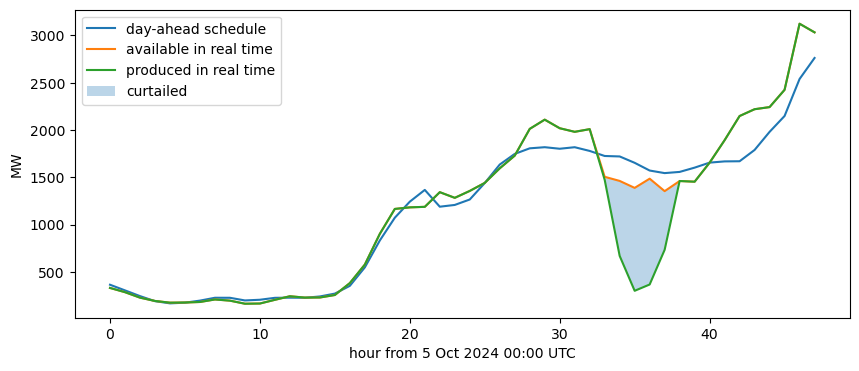

Wind curtailed in Belgium: 3651 MWh over 48 hours, in 5 hours


In [6]:
da_frames = res_da.get_dispatch_frames()
rt_frames = res_rt.get_dispatch_frames()
gen_rt = res_rt.grid.generator
area_rt = gen_rt["node"].map(res_rt.grid.node.set_index("id")["area"])
be_wind = gen_rt.index[(area_rt == "BE") & gen_rt["type"].isin(["wind_on", "wind_off"])]

wind = pd.DataFrame(
    {
        "day-ahead schedule": da_frames["generator_output"][be_wind].sum(axis=1),
        "available in real time": available_mw(profiles_rt, be_wind).sum(axis=1),
        "produced in real time": rt_frames["generator_output"][be_wind].sum(axis=1),
    }
)
wind["curtailed"] = (wind["available in real time"] - wind["produced in real time"]).clip(lower=0)
ax = wind.drop(columns="curtailed").plot(figsize=(10, 4), ylabel="MW", xlabel="hour from 5 Oct 2024 00:00 UTC")
ax.fill_between(wind.index, wind["produced in real time"], wind["available in real time"], alpha=0.3, label="curtailed")
ax.legend()
plt.show()
print(f"Wind curtailed in Belgium: {wind['curtailed'].sum():.0f} MWh over 48 hours, "
      f"in {int((wind['curtailed'] > 1).sum())} hours")

How Belgium balanced the forecast errors: the change in generation from day-ahead to real
time, summed over the 48 hours, by kind of unit.

In [7]:
be_rows = gen_rt.index[area_rt == "BE"]
change = (rt_frames["generator_output"][be_rows].sum() - da_frames["generator_output"].reindex(columns=be_rows, fill_value=0).sum())
by_type = change.groupby(gen_rt.loc[be_rows, "type"]).sum().round()
print("Change in generation, real time minus day-ahead, Belgium (MWh):")
print(by_type.to_string())

Change in generation, real time minus day-ahead, Belgium (MWh):
type
battery          -112.0
biomass             0.0
fossil_gas       -346.0
fossil_other       -0.0
hydro            -657.0
nuclear             0.0
solar           10296.0
wind_off        -2519.0
wind_on          1254.0


## Notes

- The excerpt is two days of a calibration case, meant to show the method. Curtailment
  statistics need whole years and the study-specific processing of WILLOW D4.5.
- The prices of the real-time run set the merit order of balancing; they are not market
  prices.
- `willow_rt_inputs/channels.csv` lists every day-ahead value the real-time run reads and
  the rows that use it.